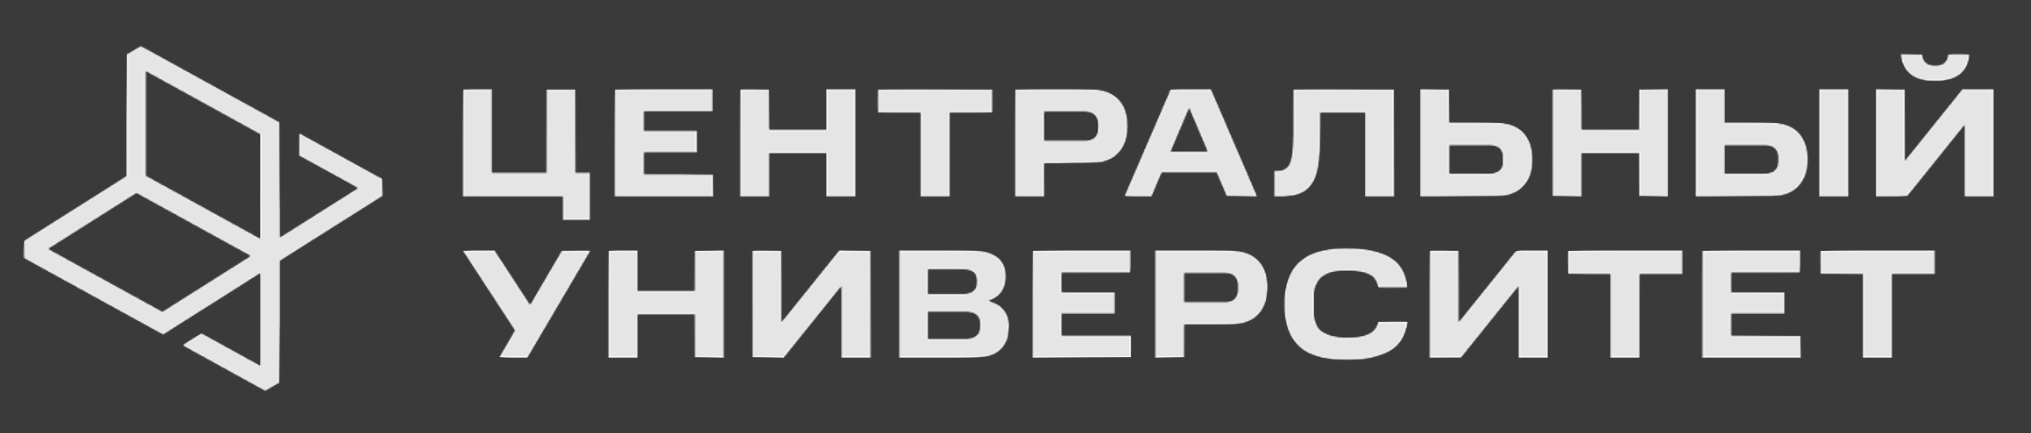


# Курс по прогнозированию временных рядов

# Неделя 10

## 10.5. Рекуррентные нейронные сети для прогнозирования ВР: LTSM, GRU, Vanilla

В сегодняшнем уроке будет дано практическое введение в применение рекуррентных нейронных сетей (РНС) к временным рядам: три варианта РНС станут методами, демонстрирующих анализ временных рядов в Python.

Darts использует библиотеку PyTorch.

Darts предлагает три вида RNN:
1. LSTM
2. GRU
3. Vanilla

Обертка позволит нам использовать RNN параллельно с другими методами прогнозирования, доступными в Darts, а затем провести их сравнение.

Одной из наиболее важных констант, которую вы хотите установить, является количество эпох в конфигурации нейронной сети. Для отладки или тестирования установите низкое значение, например 3. Для получения реального прогноза установите значение 300. Обратите внимание, что блокнот Jupyter с тремя вариантами RNN потребует примерно 2-5 минут для обучения одной модели, если вы установите константу эпохи равной 300 - считайте, что это долгая прогулка. При значении эпохи 3 он справится с кодом за несколько секунд, но, конечно, средние абсолютные процентные ошибки будут смехотворно высокими.

In [86]:
EPOCH = 300

In [87]:
%matplotlib inline
import matplotlib.pyplot as plt

import numpy as np
import pandas as pd


import torch.optim as optim
#from torch.utils.tensorboard import SummaryWriter

from darts.dataprocessing.transformers import Scaler
from darts.models import RNNModel, Theta
from darts.metrics import mape, rmse, r2_score
from darts.utils.statistics import check_seasonality, plot_acf
from darts.utils.timeseries_generation import datetime_attribute_timeseries

from darts.datasets import AirPassengersDataset

import sys
import time
import warnings
warnings.filterwarnings("ignore")
import logging
logging.disable(logging.CRITICAL)

В этом примере мы сосредоточимся на классическом наборе данных  по ежемесячным пассажирам авиалиний.

В примере с авиапассажирами выбераем даты с 1 января 1959 года для начала тестового периода, выраженного в константе `FC_START`. Мы собираемся прогнозировать на 36 месяцев, введенных в константу `FC_N`.

In [ ]:
FC_N = 36               # горизонт прогнозирования
FC_STRIDE = 10
FC_START = "19590101"   # начало тестового набора

# Загрузка и подготовка данных

In [88]:
## load data
ts = AirPassengersDataset().load()

series = ts  
df = ts.pd_dataframe()
df

component,#Passengers
Month,
1949-01-01,112.0
1949-02-01,118.0
1949-03-01,132.0
1949-04-01,129.0
1949-05-01,121.0
...,...
1960-08-01,606.0
1960-09-01,508.0
1960-10-01,461.0


Одномерный временной ряд состоит из 144 месяцев, которые охватывают период с 1949 по 1960 год.

Функция `pd_dataframe()` может преобразовать объект `timeseries` в `dataframe`, чтобы облегчить работу с ним, когда мы хотим использовать методы работы с данными, предлагаемые `pandas`.

In [89]:
series.describe()

component,#Passengers
count,144.000
mean,280.299
std,119.966
min,104.000
25%,180.000
50%,265.500
75%,360.500
max,622.000


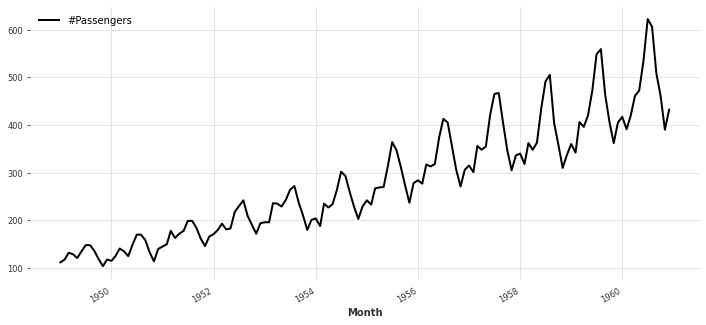

In [90]:
# plot the observations
plt.figure(100, figsize=(12, 5))
series.plot()

Функция Darts `check_seasonality()` оценивает автокорреляционную функцию ACF и возвращает порядок сезонности 12,0 месяцев.

In [91]:
# analyze its seasonality

is_seasonal, periodicity = check_seasonality(ts, max_lag=240)
dict_seas ={
    "is seasonal?":is_seasonal, 
    "periodicity (months)":f'{periodicity:.1f}', 
    "periodicity (~years)": f'{periodicity/12:.1f}'}
_ = [print(k,":",v) for k,v in dict_seas.items()]

is seasonal? : True
periodicity (months) : 12.0
periodicity (~years) : 1.0


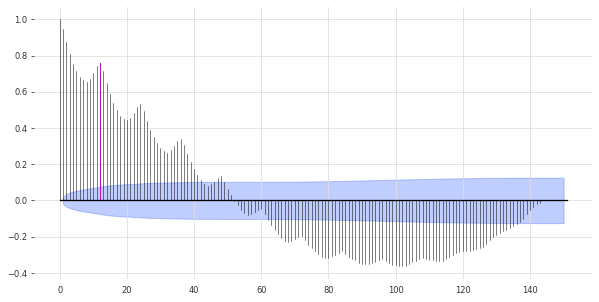

In [92]:
# plot ACF
plot_acf(ts, periodicity, max_lag=150)

Мы разделили временной ряд на обучающий и проверочный наборы данных.
В ячейке зависимостей мы выбрали FC_START = 1959/01/01 - 2 года до окончания временного ряда - в качестве точки, где мы хотим сделать срез.

In [93]:
# split training vs test dataset
train, val = ts.split_after(pd.Timestamp(FC_START))

Перед подачей исходных данных в нейронную сеть их необходимо нормализовать, применив функцию `Scaler()`.

In [94]:
# normalize the time series

trf = Scaler()
# fit the transformer to the training dataset
train_trf = trf.fit_transform(train)
# apply the transformer to the validation set and the complete series 
val_trf = trf.transform(val)
ts_trf = trf.transform(ts)

Добавим в данные признаки `year` и `month`.

In [95]:
# create month and year covariate series

year_series = datetime_attribute_timeseries(
    pd.date_range(start=series.start_time(), 
        freq=ts.freq_str, 
        periods=1000),
    attribute='year', 
    one_hot=False)
year_series = Scaler().fit_transform(year_series)

month_series = datetime_attribute_timeseries(
    year_series, 
    attribute='month', 
    one_hot=True)

covariates = year_series.stack(month_series)
cov_train, cov_val = covariates.split_after(pd.Timestamp(FC_START))

# 4. Настройка моделей RNN и их запуск


Функция `run_RNN()` настраивает нейронную сеть.

RNN поставляются с набором гиперпараметров, которые пользователь должен задать (или поручить алгоритму настройки многократно оценивать модель в поисках все более совершенных параметров), среди них:
- количество входных узлов, скрытых слоев и их узлов, выходных узлов (number of input nodes, hidden layers and their nodes, output nodes), чем их больше, тем более сложные паттерны может обрабатывать RNN; 
- значения весов и скорость их изменения (скорость обучения)
- скорость отсева (dropout), если таковая имеется.

Ограничимся несколькими различными значениями для количества эпох (циклов обучения) и для скорости обучения.
- Параметр модели принимает `flavor` каждого из трех процессов обучения, которые мы хотим применить к исходным данным: сначала LSTM, затем GRU, и, наконец, Vanilla (просто обозначенная как "RNN" в качестве варианта по умолчанию).
- Параметр `epoch` нейронной сети задает количество проходов во время обучения. Одна эпоха включает в себя один прямой и один обратный проход по всему набору данных для обучения.
- Мы установили `input_chunk_length` - количество прошлых периодов, которые будут использоваться для прогнозирования - на периодичность 12.0, которую вернул тест `check_seasonality`. Для расчета прогнозов RNN будет оглядываться на 12 месяцев назад, т.е. на полный сезонный цикл. Мы можем увеличить это значение и тем самым заставить RNN больше полагаться на свою долгосрочную память. Это сыграет на руку LSTM или - GRU по сравнению с более короткой памятью Vanilla flavor, но не обязательно приведет к более высокой точности.
- `training_length` - количество периодов, которые будут использоваться во время обучения. Не должно быть меньше, чем длина входного_куска, который будет использоваться для предсказаний.
- `dropout` - во время обучения, если установлено значение больше 0, RNN может случайным образом обнулять некоторые входы, причем вероятность обнуления равна значению параметра, для имитации различных архитектур сети. 
- `optimizer_kwargs` своим аргументом `lr` задает скорость обучения. 
- `hidden_dim` управляет размером скрытого состояния, глубиной модели. Чем больше скрытое состояние, тем более сложные закономерности она может вывести из исходных данных.
- `force_reset` отбрасывает все предыдущие модели с тем же именем, чтобы начать обучение с чистого листа.


Когда вспомогательная функция `fit_it()` вернет обученную модель, основная функция `run_RNN()` возьмет ее и использует для расчета прогнозов.

`run_RNN()` вызывает функцию `plot_fitted()` для построения графика прогноза вместе с фактическими наблюдениями.

In [ ]:
# helper function: plot the predictions

def plot_fitted(pred, act, flavor):
    plt.figure(figsize=(12,5))
    act.plot(label='actual')
    pred.plot(label='prediction')
    plt.title("RNN: {0} flavor".format(flavor) + ' | MAPE: {:.2f}%'.format(mape(pred, act)))
    plt.legend();

После построения графиков прогноза `run_RNN()` обращается к следующей вспомогательной функции, `accuracy_metrics()`, для вычисления показателей точности прогноза.

В верхней части функции `accuracy_metrics()` используется функция Darts `slice_intersect()`, чтобы убедиться, что два ряда, которые мы хотим сравнить - прогнозный и фактический - имеют одинаковую длину.

Функция вычисляет три метрики: MAPE, RMSE и R-квадрат.

R-квадрат выражает, в какой степени изменения в фактических наблюдениях могут быть объяснены соответствующими изменениями в прогнозируемых значениях. Значение 1,0 указывает на то, что прогноз идеально отражает фактические данные. Если вы задаетесь вопросом, почему R-квадрат показывает отрицательное значение: Хотя R-квадрат сам по себе является неотрицательным числом от 0 до 1, то здесь изменен его знак, чтобы согласовать его направленность с другими показателями.  Отрицательный знак перед R-squared делает его метрикой "ниже-лучше", как и другие показатели, что поможет визуализировать их на графике.

Функция также вычисляет RMSPE, среднеквадратичную процентную ошибку; и стандартную ошибку прогноза.

In [ ]:
# helper function: compute accuracy metrics
   
def accuracy_metrics(pred, act):
    act2 = act.slice_intersect(pred)
    pred2 = pred.slice_intersect(act2)
    resid = pred2 - act2
    sr = resid.pd_series()
    sa = act2.pd_series()
    sp = pred2.pd_series()
    res_mape = mape(pred2, act2)
    res_r2 = r2_score(pred2, act2)
    res_rmse = rmse(pred2, act2)
    res_pe = sr / sa
    n_act = len(act2)
    res_rmspe = np.sqrt(np.sum(res_pe**2) / n_act)    # root mean square percentage error
    res_std = np.std(sr)                               # std error of the model = std deviation of the noise
    res_se = res_std / np.sqrt(n_act)                  # std error in estimating the mean
    res_sefc = np.sqrt(res_std + res_se**2)            # std error of the forecast
    
    res_accuracy = {
        "MAPE":res_mape,"RMSPE":res_rmspe, "RMSE":res_rmse, 
        "-R squared":-res_r2, "se": res_sefc}
    return res_accuracy

In [99]:
# set up, fit, run, plot, and evaluate the RNN model

def run_RNN(flavor, ts, train, val):

    # set the model up
    model_RNN = RNNModel(
        model=flavor,
        model_name=flavor + str(" RNN"),
        input_chunk_length=periodicity,
        training_length=20,
        hidden_dim=20,
        batch_size=16,
        n_epochs=EPOCH,
        dropout=0,
        optimizer_kwargs={'lr': 1e-3},
        log_tensorboard=True,
        random_state=42,
        force_reset=True)
        
    if flavor == "RNN": flavor = "Vanilla" 

    # fit the model
    fit_it(model_RNN, train, val, flavor)

    # compute N predictions
    pred = model_RNN.predict(n=FC_N, future_covariates=covariates) 

    # plot predictions vs actual
    plot_fitted(pred, ts, flavor)

    # print accuracy metrics
    res_acc = accuracy_metrics(pred, ts)    
    print(flavor + " : ")
    _ = [print(k,":",f'{v:.4f}') for k,v in res_acc.items()]

    return [pred, res_acc]
    

После создания модели мы передаем ее в функцию `fit_it()` вместе с тренировочным и валидационным наборами данных.

In [ ]:
# helper function: fit the RNN model

def fit_it(model, train, val, flavor):
    t_start =  time.perf_counter()
    print("\nbeginning the training of the {0} RNN:".format(flavor))

    res = model.fit(train,
             future_covariates=covariates,
             val_series=val,
             val_future_covariates=covariates,
             verbose=True)

    res_time = time.perf_counter() - t_start
    print("training of the {0} RNN has completed:".format(flavor), f'{res_time:.2f} sec')

    return res

Когда вспомогательная функция `fit_it()` вернет обученную модель, основная функция `run_RNN()` возьмет ее и использует для расчета прогнозов.

`run_RNN()` вызывает функцию `plot_fitted()` для построения графика прогноза вместе с фактическими наблюдениями.

Список `flavors` содержит три варианта RNN, которые мы хотим запустить на временном ряду.
Список comprehension последовательно вызывает три варианта и передает их в RNN-прогнозист `run_RNN`. Кроме названий трех вариантов, они не отличаются по требуемой параметризации. Просто их внутренние алгоритмы приведут к разным результатам. Прогнозист `run_RNN` будет принимать в качестве входных аргументов название алгоритма, который он должен применить, а также измененный или преобразованный временной ряд с обучающим и проверочным наборами данных.

В верхней части ячейки зависимостей вы можете уменьшить параметр `EPOCH` до гораздо меньшего значения, чем 300, например, до числа эпохи 3, если вы хотите просто запустить скрипт для тестирования кода в течение минуты, если вас не интересуют точные результаты прогнозирования.


beginning the training of the LSTM RNN:


  0%|          | 0/300 [00:00<?, ?it/s]

training of the LSTM RNN has completed: 764.32 sec
LSTM : 
MAPE : 4.1133
RMSPE : 0.0449
RMSE : 0.0399
-R squared : -0.9505
se : 0.1653

beginning the training of the GRU RNN:


  0%|          | 0/300 [00:00<?, ?it/s]

training of the GRU RNN has completed: 785.79 sec
GRU : 
MAPE : 5.0073
RMSPE : 0.0532
RMSE : 0.0503
-R squared : -0.9124
se : 0.1797

beginning the training of the Vanilla RNN:


  0%|          | 0/300 [00:00<?, ?it/s]

training of the Vanilla RNN has completed: 752.47 sec
Vanilla : 
MAPE : 3.9287
RMSPE : 0.0444
RMSE : 0.0453
-R squared : -0.9208
se : 0.1858


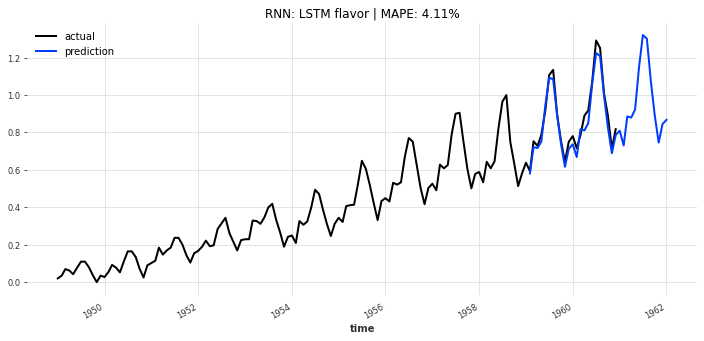

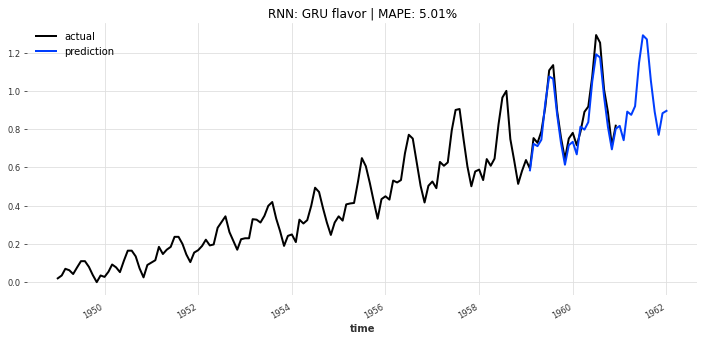

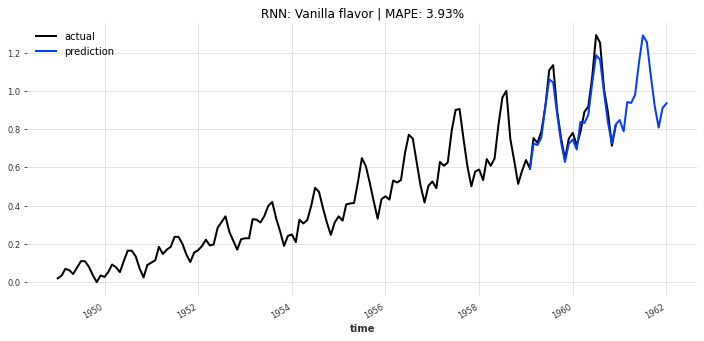

In [100]:
# run 3 different flavors of RNN on the time series:
flavors = ["LSTM", "GRU", "RNN"]

# call the RNN model setup for each of the 3 RNN flavors
res_flavors = [run_RNN(flv, ts_trf, train_trf, val_trf) for flv in flavors]

# Анализ результатов прогнозирования

Оказалось, что простая RNN Vanilla генерирует прогнозы с наименьшей средней абсолютной процентной ошибкой - 3,93%, опережая на волосок все три варианта RNN для данного конкретного примера. LSTM не сильно отстает - 4,11%. Для практических целей они неотличимы. MAPE варианта GRU - 5,01% - значительно отстает от этих двух лидеров.

В нашей настройке модели RNN мы приложили относительно небольшую скорость обучения - 0,001. Мы также могли бы поиграть с параметром dropout и с размером hidden state (более высокое значение скрытой размерности увеличивает способность RNN работать с более сложными паттернами в течение более длительного времени). Но этот конкретный временной ряд не очень сложный. Маловероятно, что трудоемкие усилия по настройке позволят снизить MAPE с 4% до, скажем, 1%. 

# Сравнение с Theta методом

Для сравнения методов RNN с базовым прогнозом используем метод Theta.

Настраиваем его параметр theta путем перебора 100 альтернативных значений. Затем мы передаем оптимальный параметр тэта в модель  и вычисляем прогнозы.

Далее строится кривая прогноза и рассчитываются показатели точности.

Theta forecast has completed:  4.79 sec
MAPE : 3.1119
RMSPE : 0.0448
RMSE : 20.4686
-R squared : -0.8987
se : 6.2176


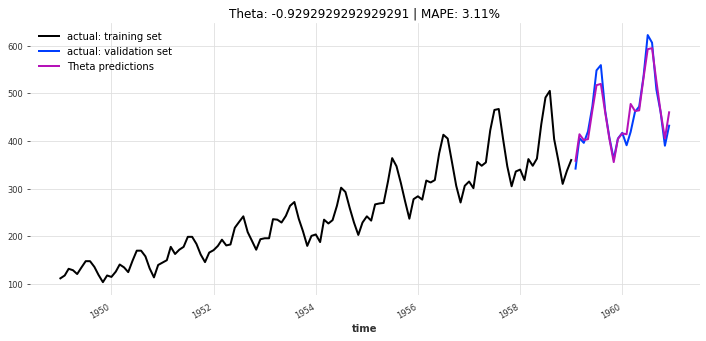

In [101]:
# Theta forecaster

# search space for best theta value: check 100 alternatives
thetas = 2 - np.linspace(-10, 10, 100)

# initialize search
best_mape = float('inf')
best_theta = 0
t_start =  time.perf_counter()
# search for best theta among 100 values, as measured by MAPE
for theta in thetas:
    model = Theta(theta)
    res = model.fit(train)
    pred_theta = model.predict(len(val))
    res_mape = mape(val, pred_theta)
    if res_mape < best_mape:
        best_mape = res_mape
        best_theta = theta


# fit the model
best_theta_model = Theta(best_theta)
best_theta_model.fit(train)
pred = best_theta_model.predict(len(val))

# review the Theta results
plt.figure(figsize=(12,5))
train.plot(label='actual: training set')
val.plot(label='actual: validation set')
pred.plot(label='Theta predictions')
plt.title("Theta: {0}".format(best_theta) + ' | MAPE: {:.2f}%'.format(mape(pred, val)))
plt.legend();

res_time = time.perf_counter() - t_start
res_acc = accuracy_metrics(pred, val)
print("Theta forecast has completed: ", f'{res_time:.2f} sec')
_ = [print(k,":",f'{v:.4f}') for k,v in res_acc.items()]
results = [pred, res_acc]


Theta дает MAPE всего 3,11%.

Чтобы было проще сравнивать методы, давайте соберем показатели точности трех вариантов RNN и прогноза Theta в одном словаре.

In [103]:
# собрать показатели точности пметодов в таблицу

dict_models = {"LSTM":res_flavors[0][1], "GRU":res_flavors[1][1],
    "Vanilla":res_flavors[2][1], "Theta":res_acc}
df_acc = pd.DataFrame.from_dict(dict_models, orient="index").T
pd.set_option("display.precision",3)
df_acc.style.highlight_min(color="lightgreen", axis=1).highlight_max(color="yellow", axis=1)

,LSTM,GRU,Vanilla,Theta
MAPE,4.113,5.007,3.929,3.112
RMSPE,0.045,0.053,0.044,0.045
RMSE,0.040,0.050,0.045,20.469
-R squared,-0.951,-0.912,-0.921,-0.899
se,0.165,0.180,0.186,6.218



Мы видим, что метод Theta лидирует по критерию MAPE: ошибка предсказания составляет всего 3,112%.

<div class="admonition note" name="html-admonition" style="background: rgba(0,184,212,.1); padding-top: 0px; padding-bottom: 6px; border-radius: 8px; border-left: 8px solid #00b8d4; border-color: #00b8d4; padding-left: 10px; padding-right: 10px;">

<p class="title">
    <i style="font-size: 18px; color:#00b8d4;"></i>
    <b style="color: #00b8d4;">&#9998 Note</b>
</p>

Абсолютные ошибки для нейронных сетей вычислины после нормировки, а для метода Theta похоже в исходном масштабе. Упс :(


Среди нейронок Лидирует LSTM.